# Session 2 — The transformer block

Session 1 wrote attention out and found heads with identifiable jobs. A transformer is that attention surrounded by a few other pieces, repeated 12 times in GPT-2 small. This session writes one block in about 30 lines of PyTorch, loads GPT-2's weights into it, and checks that twelve copies reproduce GPT-2's output. We then use the block to see what the residual stream is, and look at how position gets into a model that otherwise cannot tell the order of its tokens.

**By the end of the session you should be able to:**

1. list the parts of a pre-norm transformer block, say which of them mix positions and which work on each position separately, and say where the parameters are;
2. describe the residual stream as a running total that every block adds to, and read it with the logit lens;
3. explain why attention needs position information, and compare learned, sinusoidal and rotary positions.

**To run it yourself** you need `numpy`, `pandas`, `matplotlib`, `torch` and `transformers`, and the GPT-2 download from Session 0. The outputs are already saved in the notebook. It runs in about 30 seconds on a GPU or a laptop CPU. Numbers may differ in the last digit.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, torch.nn as nn, torch.nn.functional as F
from aij_common import DEVICE, set_seed, load_gpt2
set_seed(0)
tok, gpt2 = load_gpt2()
cfg = gpt2.config
print(f"GPT-2 small: {cfg.n_layer} blocks, d_model {cfg.n_embd}, {cfg.n_head} heads, MLP width {4 * cfg.n_embd}")

GPT-2 small: 12 blocks, d_model 768, 12 heads, MLP width 3072


The next cell holds two small helpers: one turns text into token ids, and one adds the token and position embeddings that the first block receives. Presenters skip it on screen.

In [2]:
def prompt_ids(text): return tok(text, return_tensors="pt").input_ids.to(DEVICE)

def embed(ids):
    """Token embedding plus learned position embedding: what the first block receives."""
    return gpt2.transformer.wte(ids) + gpt2.transformer.wpe(torch.arange(ids.shape[1], device=ids.device))

## 1. One block in code

A GPT-2 block does two things to a sequence of vectors $x$ (one per token, each of length $d_{\text{model}}=768$):

1. **Mix positions.** Layer-normalise, run multi-head causal attention, add the result back to $x$.
2. **Transform each position.** Layer-normalise, pass each vector through a two-layer MLP with a hidden width of $4\times768=3072$, add the result back.

The additions are the **residual connections**. In formulas, with the layer norm written $\operatorname{LN}$:

$$
x' = x + \operatorname{Attn}(\operatorname{LN}(x)),\qquad y = x' + \operatorname{MLP}(\operatorname{LN}(x')).
$$

Normalising before each sub-layer, inside the residual branch, is called **pre-norm**. It is GPT-2's layout. The original 2017 transformer normalised after the addition (post-norm), and the class below supports both with `pre=False`. The attention itself is the computation from Session 1, here through PyTorch's fused function.

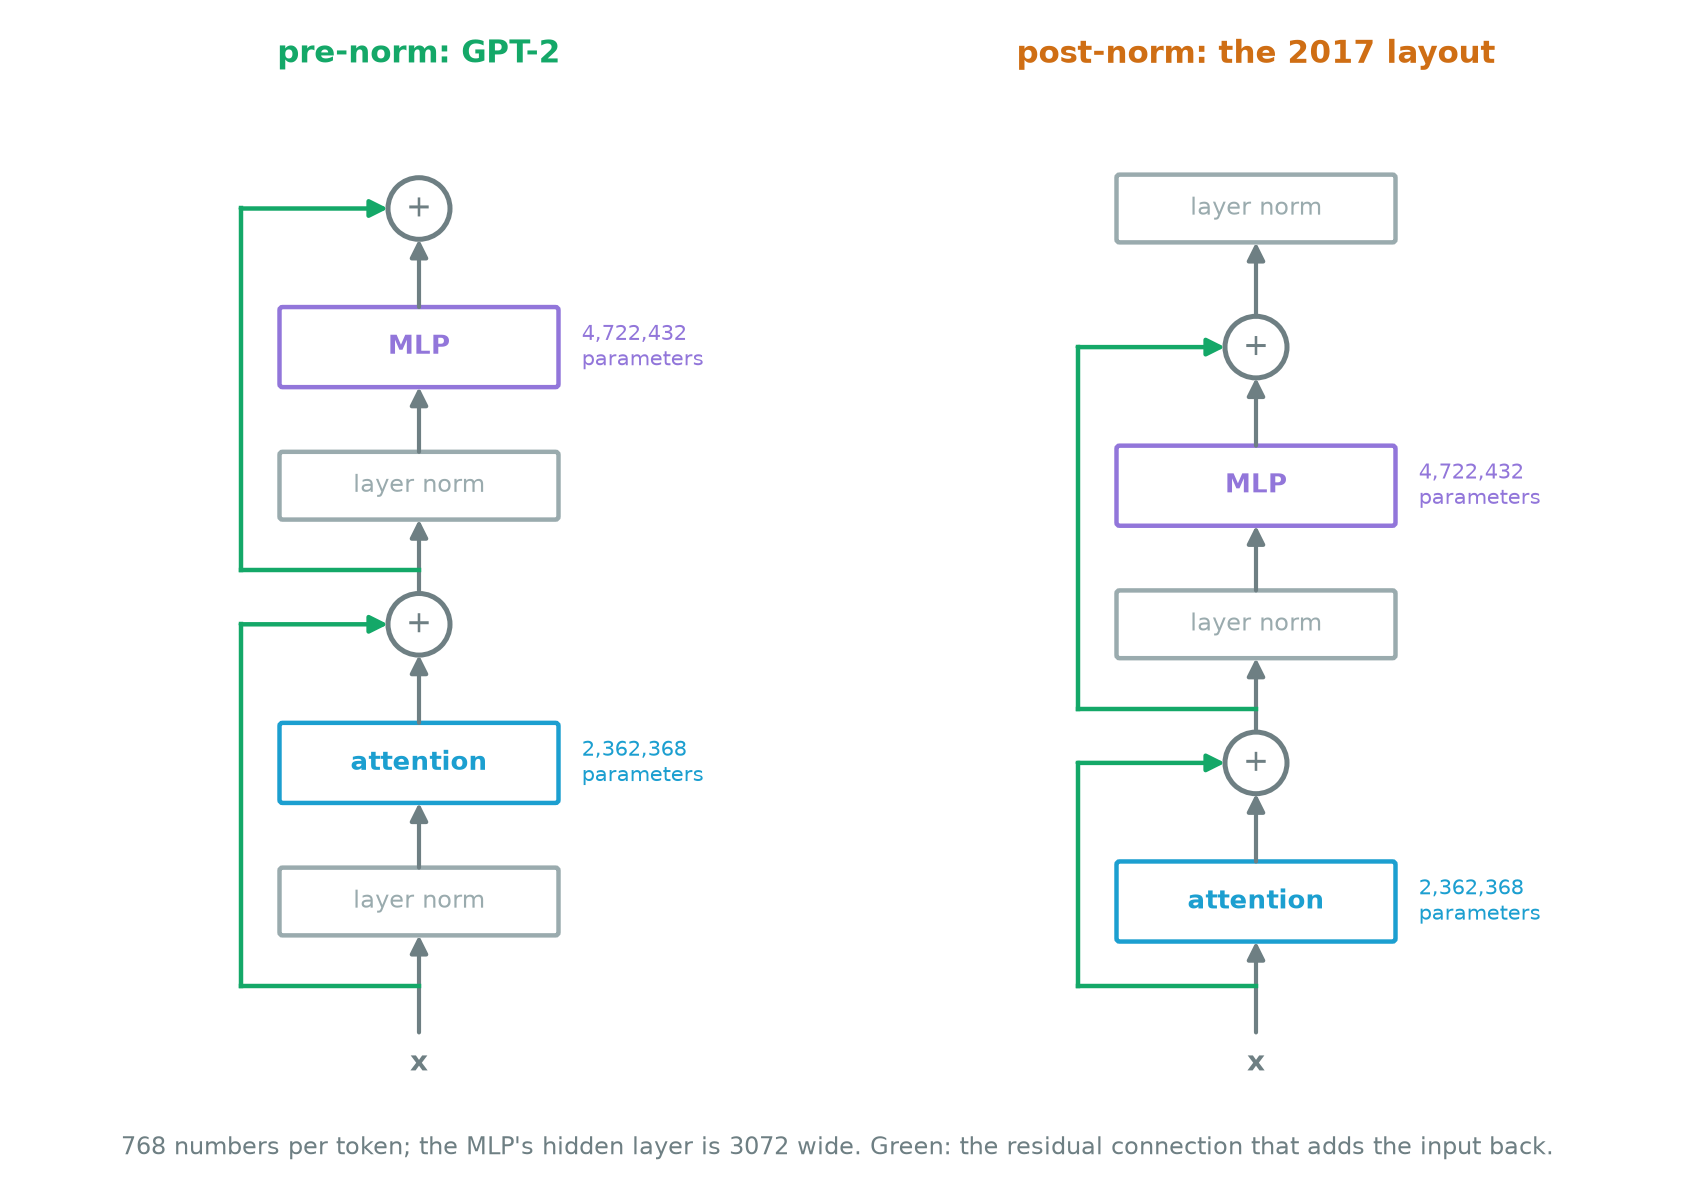

*Figure 2.1 — One GPT-2 block, pre-norm, with post-norm beside it. Pre-norm normalises inside each branch and adds the result back to the stream; post-norm normalises after the addition. Attention holds 2,362,368 of a block's parameters and the MLP 4,722,432.*

In [3]:
class Block(nn.Module):
    """One transformer block. pre=True is the GPT-2 layout: x + Attn(LN(x)), then x + MLP(LN(x))."""
    def __init__(self, d=768, heads=12, pre=True, causal=True, source=None):
        super().__init__()
        self.heads, self.pre, self.causal = heads, pre, causal
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.qkv, self.proj = nn.Linear(d, 3 * d), nn.Linear(d, d)
        self.fc, self.out = nn.Linear(d, 4 * d), nn.Linear(4 * d, d)
        if source is not None:                       # copy GPT-2's weights (it stores them transposed)
            self.ln1.load_state_dict(source.ln_1.state_dict()); self.ln2.load_state_dict(source.ln_2.state_dict())
            for mine, theirs in [(self.qkv, source.attn.c_attn), (self.proj, source.attn.c_proj), (self.fc, source.mlp.c_fc), (self.out, source.mlp.c_proj)]:
                mine.weight.data, mine.bias.data = theirs.weight.data.T.clone(), theirs.bias.data.clone()

    def attn(self, x):
        B, T, D = x.shape
        q, k, v = [t.view(B, T, self.heads, -1).transpose(1, 2) for t in self.qkv(x).split(D, -1)]
        y = F.scaled_dot_product_attention(q, k, v, is_causal=self.causal)
        return self.proj(y.transpose(1, 2).reshape(B, T, D))

    def mlp(self, x): return self.out(F.gelu(self.fc(x), approximate="tanh"))

    def forward(self, x):
        if self.pre:
            x = x + self.attn(self.ln1(x))
            return x + self.mlp(self.ln2(x))
        x = self.ln1(x + self.attn(x))
        return self.ln2(x + self.mlp(x))

The class holds the whole block. Now we copy GPT-2's weights into twelve copies of it and compare with the real model on a sentence.

In [4]:
blocks = [Block(source=b).to(DEVICE).eval() for b in gpt2.transformer.h]
ids = prompt_ids("The Eiffel Tower is in the city of")
with torch.no_grad():
    ref = gpt2(ids, output_hidden_states=True)
    x = embed(ids)
    print(f"block 1 vs GPT-2: largest difference {(blocks[0](x) - ref.hidden_states[1]).abs().max():.1e}")
    for b in blocks: x = b(x)
    mine = gpt2.lm_head(gpt2.transformer.ln_f(x))
print(f"all 12 blocks, final norm and output layer vs GPT-2's logits: largest difference {(mine - ref.logits).abs().max():.1e}")
print("same next-token prediction:", tok.decode(mine[0, -1].argmax()), "|", tok.decode(ref.logits[0, -1].argmax()))

block 1 vs GPT-2: largest difference 3.8e-06
all 12 blocks, final norm and output layer vs GPT-2's logits: largest difference 6.1e-05
same next-token prediction:  Paris |  Paris


One block reproduces GPT-2's first block to within 3.8e-06. Chaining all 12 blocks, then GPT-2's final layer norm and output layer, gives logits within 6.1e-05 of the real model's and the same next-token prediction (` Paris`). This is float32 rounding, so the twelve blocks above are GPT-2, apart from the embedding step.

> **Pause:** attention mixes information between tokens, and the MLP has the bigger hidden layer. What share of a block's parameters do you expect to sit in the attention?
>
> - **A.** About two thirds.
> - **B.** About a third.
> - **C.** About a half.
> - **D.** About a tenth.
>
> Pick one before you scroll.

<details><summary>Answer</summary>

**B.** Attention holds 2,362,368 parameters (33%) and the MLP 4,722,432 (67%).

</details>

In [5]:
b = blocks[0]; groups = {"attention (qkv + output)": [b.qkv, b.proj], "MLP (expand + contract)": [b.fc, b.out], "two layer norms": [b.ln1, b.ln2]}
counts = {k: sum(p.numel() for m in v for p in m.parameters()) for k, v in groups.items()}
display(pd.DataFrame({"parameters": counts, "share of the block": {k: f"{100 * v / sum(counts.values()):.0f}%" for k, v in counts.items()}}))

,parameters,share of the block
attention (qkv + output),2362368,33%
MLP (expand + contract),4722432,67%
two layer norms,3072,0%


Two thirds of a block's parameters are in the MLP (4,722,432, or 67%) and one third in attention (2,362,368, or 33%). The layer norms hold 3,072 numbers. Twelve blocks come to about 85 million parameters. Adding the 38.6 million in the token embeddings (Session 0) and 0.8 million for 1,024 learned positions gives the model's 124 million.

So most of the model's capacity is in the part that works on each position separately. The MLP sees one token's vector at a time and uses the same weights at every position, and attention is the only place where tokens exchange information.

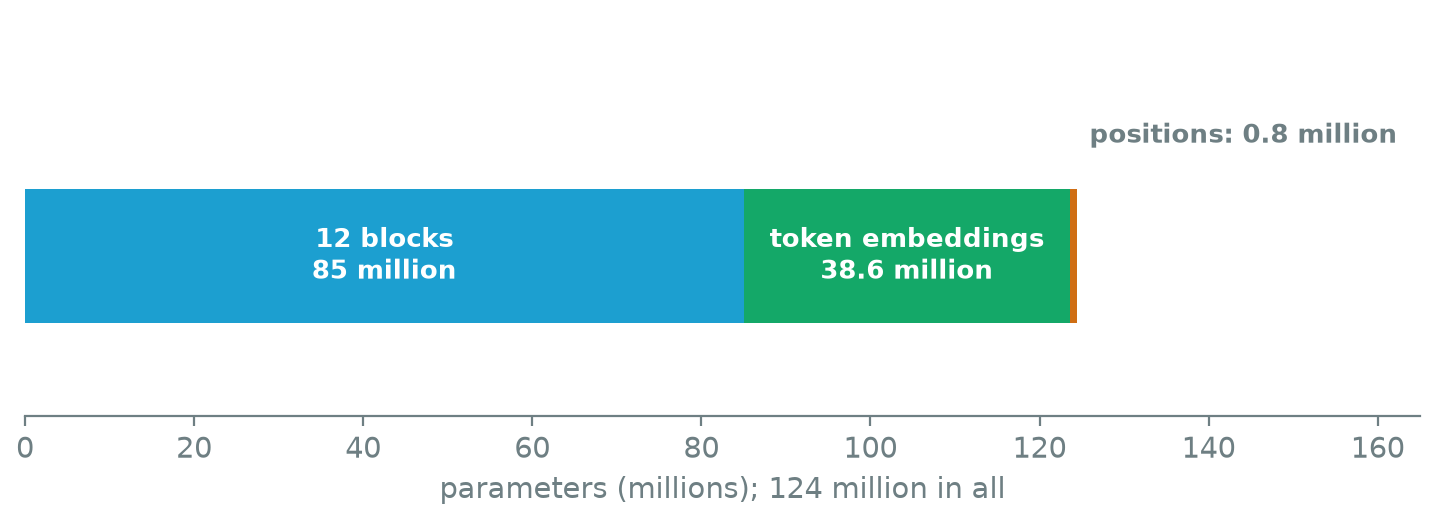

*Figure 2.2 — Where GPT-2 small's 124 million parameters are: about 85 million in the twelve blocks, 38.6 million in the token embeddings and 0.8 million in the position embeddings.*

## 2. The residual stream

Because every sub-layer adds its result to $x$ instead of replacing it, the vector for a token is a running total. Embeddings put the first entry in, and each of the 24 sub-layers (12 attention, 12 MLP) writes a correction. Mechanistic-interpretability researchers call this running total the **residual stream**. It is the one place where blocks communicate.

If this is right, the final output layer should be able to read the stream before the last block and get a rough answer. This is the **logit lens**: apply GPT-2's final layer norm and output layer to the stream after every block, and see what the model would predict if it stopped there. We use a prompt whose answer is a fact: *The Eiffel Tower is in the city of*.

> **Pause:** after which block do you expect the model's best guess to become the right city?
>
> - **A.** Early: by block 3.
> - **B.** About halfway: around block 6.
> - **C.** Late: after block 11 of 12.
> - **D.** Only at the very end of the model.
>
> Pick one before you scroll.

<details><summary>Answer</summary>

**C.** The best guess is `Paris` after block 11. The rank of the answer improves steadily, from 22680 after the embedding to 10 after block 9 and 2 after block 10, where the best guess is ` London`.

</details>

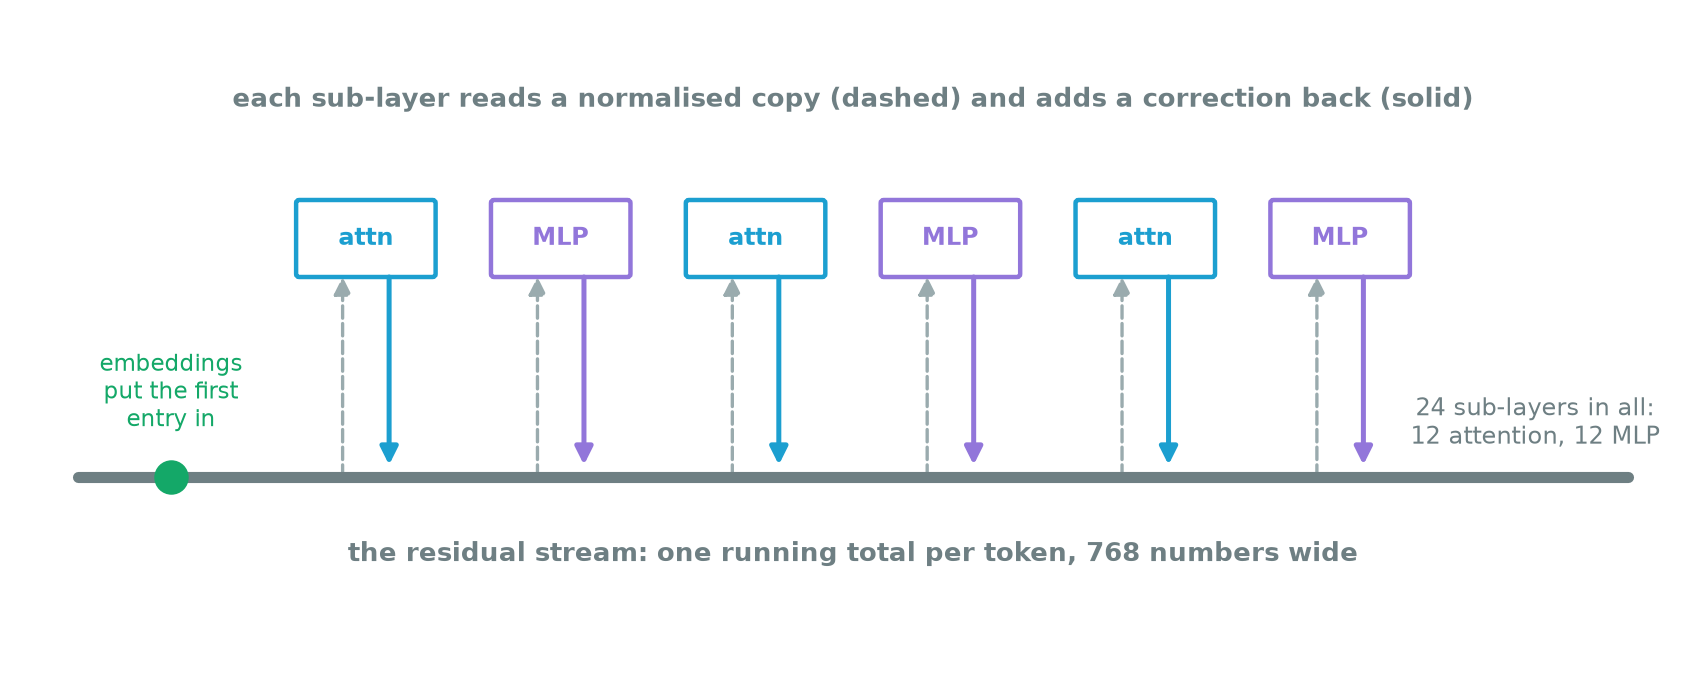

*Figure 2.3 — The residual stream. Each token's vector is a running total: the embeddings put the first entry in, and each of the 24 sub-layers (12 attention, 12 MLP) reads a normalised copy and adds a correction back.*

In [6]:
@torch.no_grad()
def lens(text):
    ids = prompt_ids(text); out = gpt2(ids, output_hidden_states=True)
    answer = out.logits[0, -1].argmax().item(); rows = []
    for layer, h in enumerate(out.hidden_states):
        logits = gpt2.lm_head(gpt2.transformer.ln_f(h) if layer < cfg.n_layer else h)[0, -1].float()   # the last entry already has the final norm
        rows.append({"after block": layer, "model's best guess": repr(tok.decode(logits.argmax())), f"p({tok.decode(answer).strip()})": round(logits.softmax(-1)[answer].item(), 4), "rank of the answer": int((logits > logits[answer]).sum() + 1)})
    return pd.DataFrame(rows).set_index("after block")
lens_table = lens("The Eiffel Tower is in the city of")
display(lens_table)

,model's best guess,p(Paris),rank of the answer
after block,,,
0,' destro',0.0000,22680
1,' the',0.0000,5042
2,' the',0.0000,4947
3,' the',0.0000,2365
4,' the',0.0000,1012
5,' the',0.0001,658
6,' the',0.0004,261
7,' East',0.0014,103
8,' Ing',0.0028,64


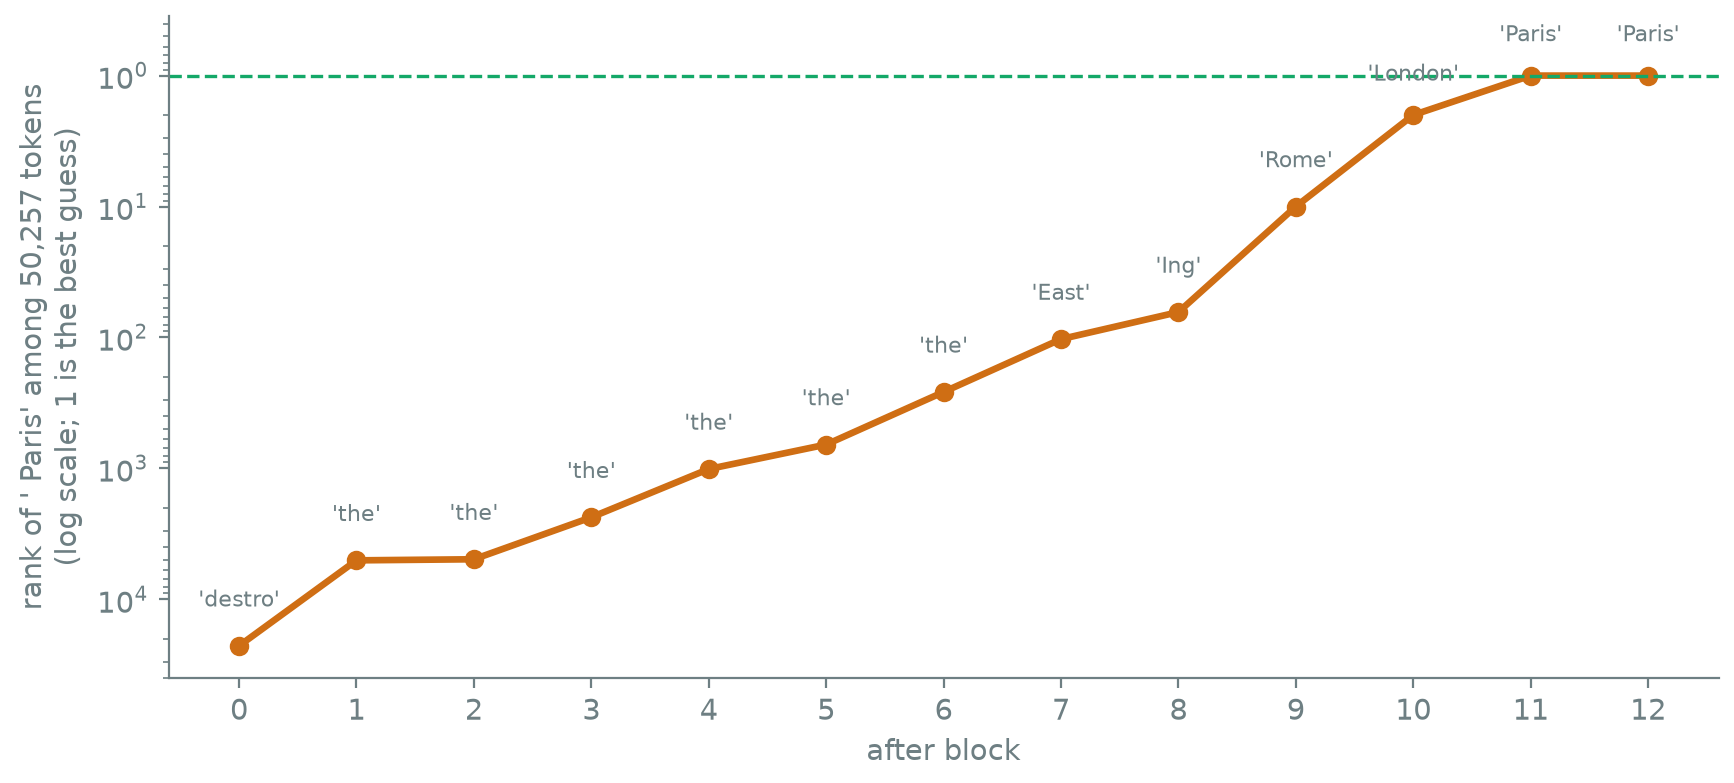

*Figure 2.4 — The logit lens on "The Eiffel Tower is in the city of". After each block the output layer is applied to the stream; the rank of ' Paris' improves from 22,680 after the embedding to 1,012 after block 4, 64 after block 8 and 2 after block 10. The label on each point is the model's best guess at that stage.*

The best guess after blocks 1 to 6 is ` the`, a safe guess for almost any text. Then it changes in steps: ` East` (block 7), ` Ing` (8), ` Rome` (9), ` London` (10), and ` Paris` after blocks 11 and 12. The rank of ` Paris` among the 50,257 tokens improves from 22,680 after the embedding to 1,012 after block 4, 261 after block 6, 64 after block 8, 10 after block 9 and 2 after block 10. The guesses from blocks 9 and 10 are both cities, so the stream narrows towards the right kind of answer before it reaches the right one.

The probability of ` Paris` is 0.25 after block 10 (rank 2, behind London), 0.18 after block 11, and 0.07 at the output. A model this small is unsure even when it is right, and its last block lowers the probability of the right answer slightly here.

Two cautions. The lens applies the output layer to states it was not trained to read, so early guesses such as ` destro` after the embedding say little. And we show one prompt. We next measure how much each sub-layer writes.

The chart shows, for the last token of the prompt, the size (norm) of the stream and of what each attention and MLP layer adds to it, on a log scale.

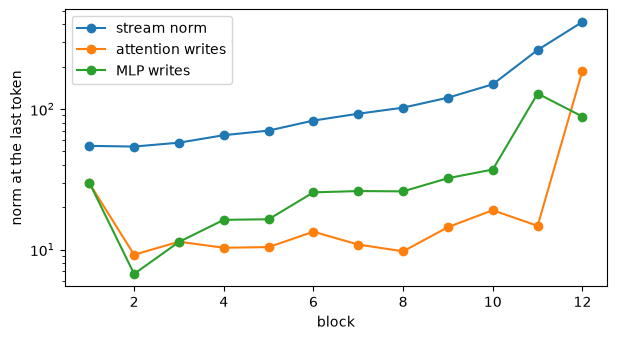

block,1,2,3,4,5,6,7,8,9,10,11,12
stream norm,54.7,54.1,57.6,65.2,70.2,82.8,92.6,102.3,120.5,150.1,263.3,417.3
attention writes,29.7,9.2,11.4,10.3,10.4,13.4,10.9,9.7,14.4,19.0,14.7,187.6
MLP writes,30.0,6.7,11.3,16.3,16.4,25.5,26.1,25.9,32.2,37.1,128.9,88.4


In [7]:
x, rows = embed(ids), []
with torch.no_grad():
    for i, b in enumerate(blocks):
        a = b.attn(b.ln1(x)); x = x + a; m = b.mlp(b.ln2(x)); x = x + m
        rows.append({"block": i + 1, "stream norm": x[0, -1].norm().item(), "attention writes": a[0, -1].norm().item(), "MLP writes": m[0, -1].norm().item()})
norms = pd.DataFrame(rows).set_index("block")
fig, ax = plt.subplots(figsize=(7, 3.6)); norms.plot(ax=ax, marker="o"); ax.set(ylabel="norm at the last token", yscale="log"); plt.show()
display(norms.round(1).T)

The stream norm grows from 54.7 after block 1 to 417.3 after block 12, so later blocks write into a stream that is already large. Early blocks add comparatively little: attention writes 9 to 13 per block in blocks 2 to 8, and the MLP 7 to 26. The size of the writes then rises. The MLP in block 11 writes 128.9, and attention in block 12 writes 187.6, nearly half of the final norm. These are numbers for one token in one prompt, so they show the kind of pattern and not a general law, but they do show that the last blocks make the largest edits.

Layer norm is why this works. Each sub-layer reads a normalised copy, so it sees a vector of a standard size however large the stream has grown.

## 3. Position

Nothing in the block so far knows the order of the tokens. We test that directly. Take 8 random vectors and a randomly initialised block. We shuffle the tokens and run the block, then run the block and shuffle its output. If the block ignores order, these will be the same. We run it twice: once with full attention (no mask) and once with the causal mask.

> **Pause:** with no position information at all, are the two results the same? And does the causal mask change the answer?
>
> - **A.** Without the mask the results are the same, and with the causal mask they differ.
> - **B.** They differ in both cases.
> - **C.** They are the same in both cases.
> - **D.** They are the same with the causal mask and differ without it.
>
> Pick one before you scroll.

<details><summary>Answer</summary>

**A.** Without a mask the two results agree to 2.4e-07, so the block treats tokens as an unordered set. With the causal mask they differ by 9.9e-01, because the mask lets later tokens see more.

</details>

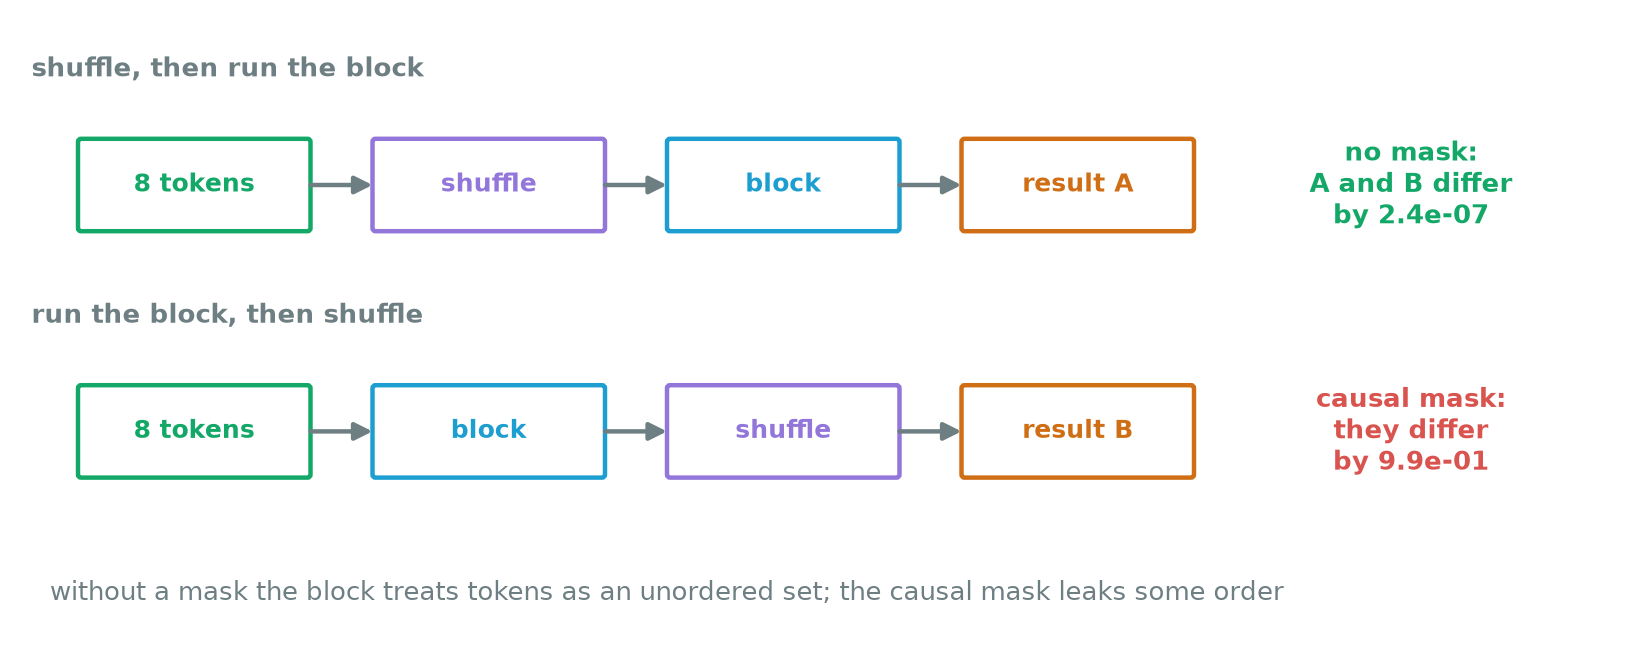

*Figure 2.5 — The shuffle test. Shuffling the tokens and then running the block gives the same result as running it and then shuffling (the largest difference is at rounding-error size, shown in the figure) when there is no mask, so the block cannot see order. With the causal mask the results differ by a large amount.*

In [8]:
set_seed(1)
x = torch.randn(1, 8, 768, device=DEVICE); perm = torch.randperm(8, device=DEVICE)
for causal in (False, True):
    blk = Block(causal=causal).to(DEVICE).eval()
    with torch.no_grad(): diff = (blk(x[:, perm]) - blk(x)[:, perm]).abs().max().item()
    print(f"{'causal mask   ' if causal else 'no mask       '} shuffle the 8 tokens, then run  vs  run, then shuffle: largest difference {diff:.1e}")

no mask        shuffle the 8 tokens, then run  vs  run, then shuffle: largest difference 2.4e-07
causal mask    shuffle the 8 tokens, then run  vs  run, then shuffle: largest difference 9.9e-01


Without a mask, the two results agree to 2.4e-07, so attention and the MLP together treat the tokens as an unordered set. With the causal mask they differ by 0.99, because a causal model gives token $i$ access to only $i+1$ tokens, and shuffling changes who can see whom. The mask carries some order information, but a model should not have to infer position from it, so GPT-2 adds position explicitly. It has one learned vector per position, up to 1,024, added to the token embedding.

The figure compares those learned vectors with the sinusoidal ones from the original transformer paper. The left panel is the cosine similarity between every pair of the first 128 learned position vectors, the middle one the same for sinusoidal vectors, and the right panel the average similarity at each distance.

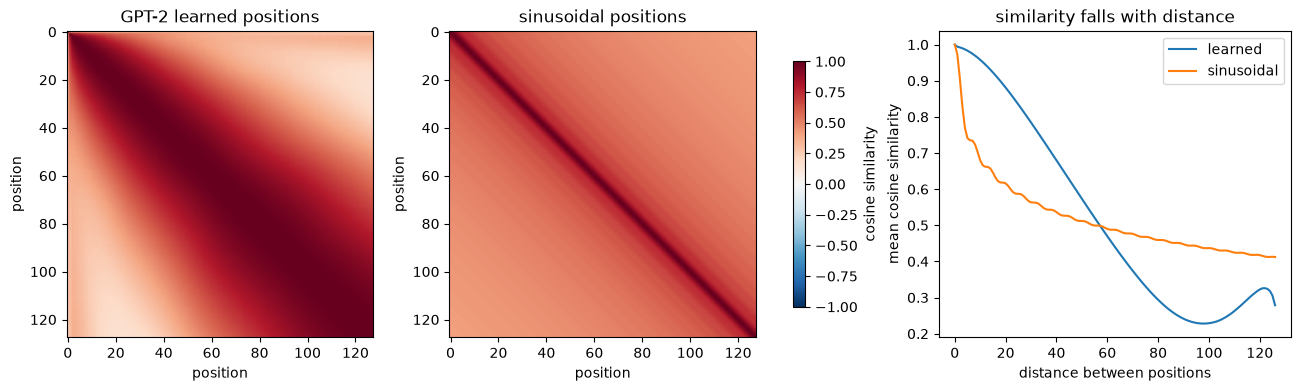

mean cosine similarity at distance 1, 10, 50, 100 (learned): [0.99, 0.96, 0.57, 0.23]
mean cosine similarity at distance 1, 10, 50, 100 (sinusoidal): [0.97, 0.68, 0.51, 0.44]
norm of the learned position vector at positions 0, 1, 100, 500, 1000, 1023: [9.88, 5.19, 3.36, 3.38, 3.67, 0.12]


In [9]:
n = 128
W = gpt2.transformer.wpe.weight.detach().float().cpu()
angles = np.arange(n)[:, None] / 10000 ** (2 * (np.arange(768)[None, :] // 2) / 768)
sinus = np.where(np.arange(768) % 2 == 0, np.sin(angles), np.cos(angles))
def cosine(M):
    M = F.normalize(torch.as_tensor(M, dtype=torch.float32), dim=1)
    return (M @ M.T).numpy()
C_learned, C_sin = cosine(W[:n]), cosine(sinus)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)
for ax, C, name in [(axes[0], C_learned, "GPT-2 learned positions"), (axes[1], C_sin, "sinusoidal positions")]:
    im = ax.imshow(C, cmap="RdBu_r", vmin=-1, vmax=1); ax.set(title=name, xlabel="position", ylabel="position")
fig.colorbar(im, ax=axes[:2], shrink=0.8, label="cosine similarity")
for C, name in [(C_learned, "learned"), (C_sin, "sinusoidal")]: axes[2].plot([np.diag(C, k).mean() for k in range(n - 1)], label=name)
axes[2].set(xlabel="distance between positions", ylabel="mean cosine similarity", title="similarity falls with distance"); axes[2].legend(); plt.show()
for name, C in [("learned", C_learned), ("sinusoidal", C_sin)]: print(f"mean cosine similarity at distance 1, 10, 50, 100 ({name}):", [round(float(np.diag(C, k).mean()), 2) for k in (1, 10, 50, 100)])
norm = W.norm(dim=1); print("norm of the learned position vector at positions 0, 1, 100, 500, 1000, 1023:", [round(norm[i].item(), 2) for i in (0, 1, 100, 500, 1000, 1023)])

GPT-2 was never told that positions are ordered, and it learned a smooth structure anyway. Nearby positions have similar vectors, and the average cosine similarity falls steadily with distance: 0.99 at distance 1, 0.96 at 10, 0.57 at 50 and 0.23 at 100. The sinusoidal vectors fall faster at first (0.68 at distance 10) and then level off, at 0.51 at distance 50 and 0.44 at 100.

The last line of output shows a quirk. The learned vectors have a norm of 9.9 at position 0 and 5.2 at position 1, then around 3.4 to 3.7 from position 100 to 1000, and only 0.12 at position 1023. The last position is almost unused. A likely reason is that few training texts reached 1,024 tokens, but we have not checked that.

Newer models such as Llama and Qwen use neither of these. They use **rotary position embeddings** (RoPE), which do not add anything to the input. Instead, queries and keys are rotated before the dot product, each pair of numbers by an angle proportional to the token's position. The rotation makes the query–key score depend only on the distance between the two tokens. The cell checks that: it uses one fixed query vector and one fixed key vector at many positions.

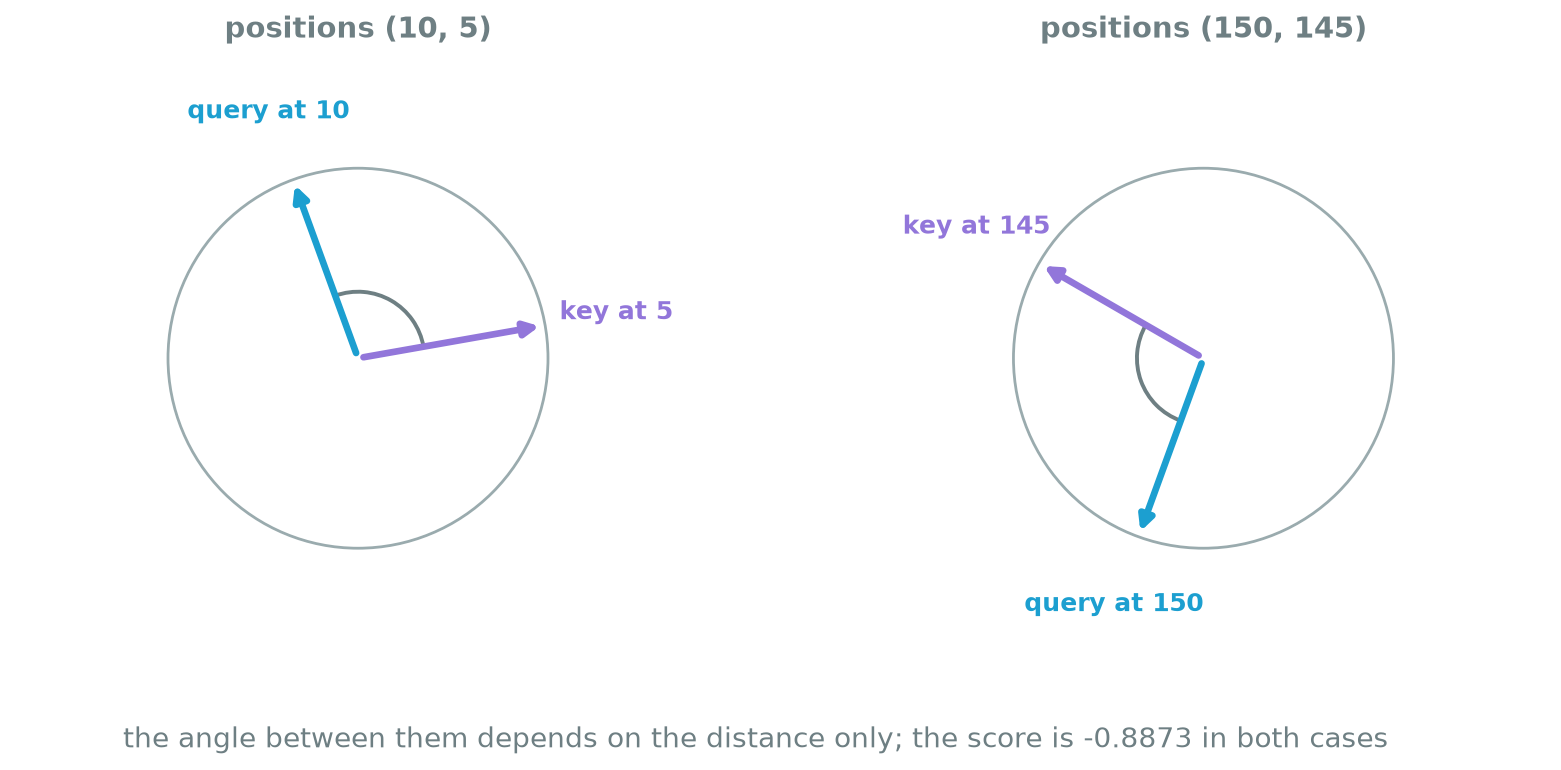

*Figure 2.6 — RoPE in two dimensions. A query at position m is rotated by an angle proportional to m, a key at position n by an angle proportional to n, so the angle between them depends on m − n alone. The notebook's score for one query and key is -0.8873 at positions (10, 5), (50, 45) and (150, 145).*

score for a fixed q and k at positions (10, 5), (50, 45), (150, 145): [-0.8873, -0.8873, -0.8873]
largest spread of the score along any diagonal (same distance, different positions): 7.5e-15


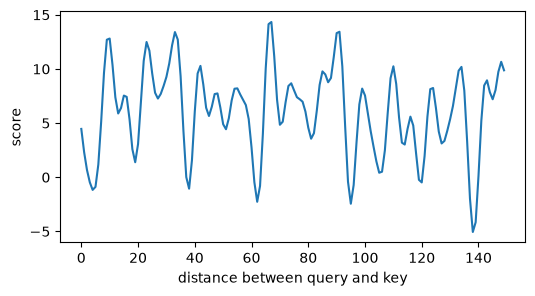

In [10]:
def rope(v, pos, base=10000):
    """Rotary position embedding: rotate each pair of numbers in v by an angle that grows with position."""
    a = pos[:, None] * base ** (-torch.arange(0, v.shape[-1], 2) / v.shape[-1])
    v1, v2 = v[..., 0::2], v[..., 1::2]
    return torch.stack([v1 * a.cos() - v2 * a.sin(), v1 * a.sin() + v2 * a.cos()], -1).flatten(-2)

set_seed(2)
q, k = torch.randn(64).double(), torch.randn(64).double(); pos = torch.arange(200).double()
S = rope(q.expand(200, 64), pos) @ rope(k.expand(200, 64), pos).T            # S[i, j] = (q rotated to i) . (k rotated to j)
spread = max(np.std(np.diag(S.numpy(), -o)) for o in range(150))
print("score for a fixed q and k at positions (10, 5), (50, 45), (150, 145):", [round(S[i, j].item(), 4) for i, j in [(10, 5), (50, 45), (150, 145)]])
print(f"largest spread of the score along any diagonal (same distance, different positions): {spread:.1e}")
plt.figure(figsize=(6, 3)); plt.plot([S[150, 150 - o].item() for o in range(150)]); plt.xlabel("distance between query and key"); plt.ylabel("score"); plt.show()

The score for the same query and key is $-0.8873$ at positions (10, 5), (50, 45) and (150, 145). Along any diagonal of the score matrix (a fixed distance, different positions) the largest spread is 7.5e-15. So the score depends only on the distance. The line plot shows the score as a function of distance for this one query and key. Each pair of numbers rotates at its own frequency, so the sum oscillates as the tokens move apart.

In a trained model the queries and keys learn to use these rotations, so that a head can prefer nearby tokens or tokens a fixed distance away. Every attention score is given the distance between the two tokens directly.

## What to take away

- A pre-norm block is $x' = x + \operatorname{Attn}(\operatorname{LN}(x))$ followed by $y = x' + \operatorname{MLP}(\operatorname{LN}(x'))$. We rebuilt GPT-2's twelve blocks and matched its logits to 6e-05.
- Attention is the only place where tokens exchange information. The MLP holds two thirds of each block's parameters and works on each position alone.
- Every sub-layer adds to a running total, the residual stream. The logit lens reads it after any block: for *The Eiffel Tower is in the city of*, the guess becomes a city at block 9 and the right city at block 11.
- Without position information the block treats tokens as an unordered set (difference 2.4e-07 after shuffling). GPT-2 learns a position vector per slot, and newer models rotate queries and keys instead (RoPE), which makes the score depend on distance only.

---

# Going deeper

*The rest of this notebook is for reading after the session.*

## Layer normalisation

For one token's vector $x\in\mathbb{R}^{d}$,

$$
\operatorname{LN}(x)=\gamma\odot\frac{x-\mu}{\sqrt{\sigma^2+\epsilon}}+\beta,\qquad \mu=\frac1d\sum_i x_i,\quad \sigma^2=\frac1d\sum_i(x_i-\mu)^2 .
$$

It acts on each token separately, over its $d$ features, which is why it works with any sequence length and batch size. Some recent models use RMSNorm, which drops the mean and the shift $\beta$ and divides by the root mean square.

## Pre-norm and post-norm

With post-norm, $y=\operatorname{LN}(x+F(x))$, the stream is renormalised after every sub-layer, so the shortcut path through the residual connection is interrupted. Xiong et al. (2020), *On Layer Normalization in the Transformer Architecture*, analysed how this affects gradients at initialisation and why post-norm models usually need a learning-rate warm-up. Pre-norm leaves the shortcut path clean, which is why almost all current decoder models use it. The cost is that the stream grows from block to block, as the chart in section 2 shows.

## The MLP

The MLP expands to $4d$, applies a nonlinearity (GELU in GPT-2) and projects back. Geva et al. (2021), *Transformer Feed-Forward Layers Are Key-Value Memories*, argued that the rows of the first matrix act like pattern detectors and the columns of the second like stored outputs. Many recent models replace the plain MLP with a gated variant (SwiGLU), which has three matrices instead of two.

## Why position information is needed at all

Attention computes $\operatorname{softmax}(QK^\top)V$, and permuting the rows of $X$ permutes the rows of $Q$, $K$ and $V$ in step, so the output permutes the same way. Section 3 verified this numerically. Haviv et al. (2022), *Transformer Language Models without Positional Encodings Still Learn Positional Information*, report that causal models trained without any position input still recover position, probably through the causal mask. We have not tested that here.

## Rotary embeddings

For a query $q$ at position $m$ and a key $k$ at position $n$, split each vector into pairs $(q_{2i},q_{2i+1})$ and rotate pair $i$ by the angle $m\theta_i$, with $\theta_i=10000^{-2i/d}$. Each rotation preserves lengths, and the dot product of a rotated query and key depends on the rotation angle difference, $(m-n)\theta_i$. Su et al. (2021), *RoFormer*, introduced the method.

## Reading the logit lens with care

The method was popularised by a blog post by nostalgebraist (2020). The intermediate states are not trained to be read by the output layer, and in some models the lens is hard to interpret in early layers. Methods that train a small readout for each layer (a "tuned lens") address that. Our one prompt illustrates the idea and is not a measurement of how GPT-2 works in general.

## Interactive explainers

Outside tools that show the same ideas live:

- [Transformer Explainer](https://poloclub.github.io/transformer-explainer/): the same blocks as this session, running live.
- [LLM Visualization](https://bbycroft.net/llm): a 3D walkthrough of a small GPT, tensor by tensor.